## Week 8 Lab Session Worksheet: Visual Encoding
This notebook contains activities and exercises for analysing and visualising the [`titanic.csv`](https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv) dataset using pandas, matplotlib, numpy and seaborn.

## Importatnt 

You need to replace `titanic.csv` in the same folder as `Week_8_Lab_Session_Worksheet`

In [5]:
# First, let's import the necessary libraries and load the data.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [6]:
# Read the Titanic dataset
df = pd.read_csv('titanic.csv')

In [7]:
#or you can load the dataset using seaborn
#load Titanic Dataset
#titanic = sns.load_dataset('titanic');
#titanic.info();

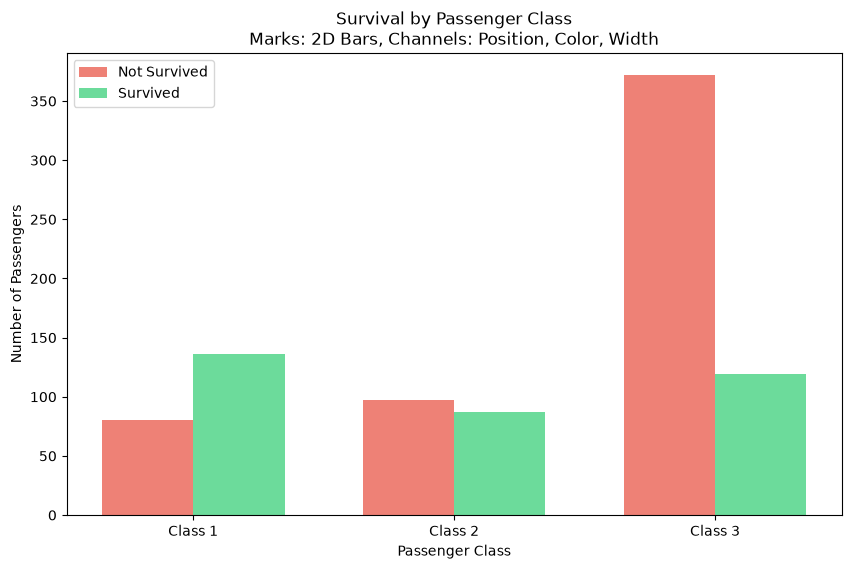

In [8]:
#Example 1: Bar Chart with Multiple Visual Channels
# Mark type: 2D Rectangles (Bars)
# Channels: Position (x,y), Color, Width
plt.figure(figsize=(10, 6))

# Calculate survival counts by passenger class
survival_by_class = df.groupby(['pclass', 'survived']).size().unstack()

# Create the bar plot with positional encoding
bar_width = 0.35
x = np.arange(len(survival_by_class.index))

# Create bars with color channel (red for not survived, green for survived)
# Add labels in the bar() function to create legend entries
plt.bar(x - bar_width/2, 
        survival_by_class[0], 
        bar_width, 
        color='#e74c3c', 
        label='Not Survived',  # Add label here
        alpha=0.7)

plt.bar(x + bar_width/2, 
        survival_by_class[1], 
        bar_width, 
        color='#2ecc71', 
        label='Survived',  # Add label here
        alpha=0.7)

# Add labels and title (textual channel)
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.title('Survival by Passenger Class\nMarks: 2D Bars, Channels: Position, Color, Width')
plt.xticks(x, ['Class 1', 'Class 2', 'Class 3'])

# Add legend - now it will work because we have labeled artists
plt.legend()

plt.show()

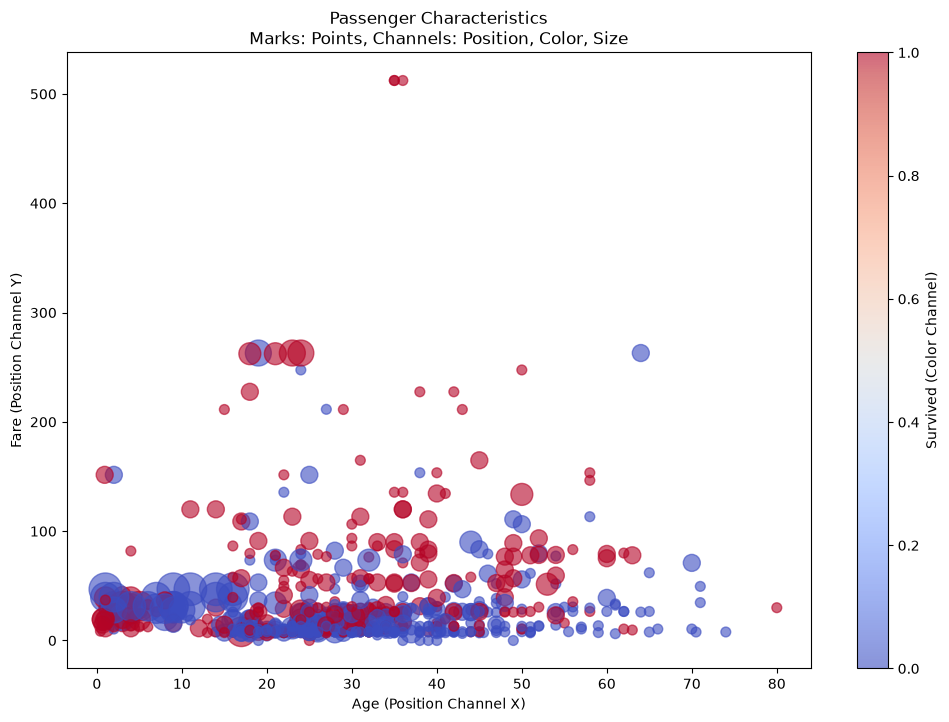

In [12]:
# Example 2: Scatter Plot with Multiple Visual Channels
# Mark type: Points (0D)
# Channels: Position (x,y), Color, Size
plt.figure(figsize=(12, 8))

# Create scatter plot using multiple channels
scatter = plt.scatter(df['age'],  # X position channel
                     df['fare'],  # Y position channel
                     c=df['survived'],  # Color channel
                     s=df['sibsp'] * 100 + 50,  # Size channel
                     alpha=0.6,
                     cmap='coolwarm')

# Add title and labels
plt.title('Passenger Characteristics\nMarks: Points, Channels: Position, Color, Size')
plt.xlabel('Age (Position Channel X)')
plt.ylabel('Fare (Position Channel Y)')

# Add colorbar to explain survival encoding
colorbar = plt.colorbar(scatter)
colorbar.set_label('Survived (Color Channel)')

plt.show()



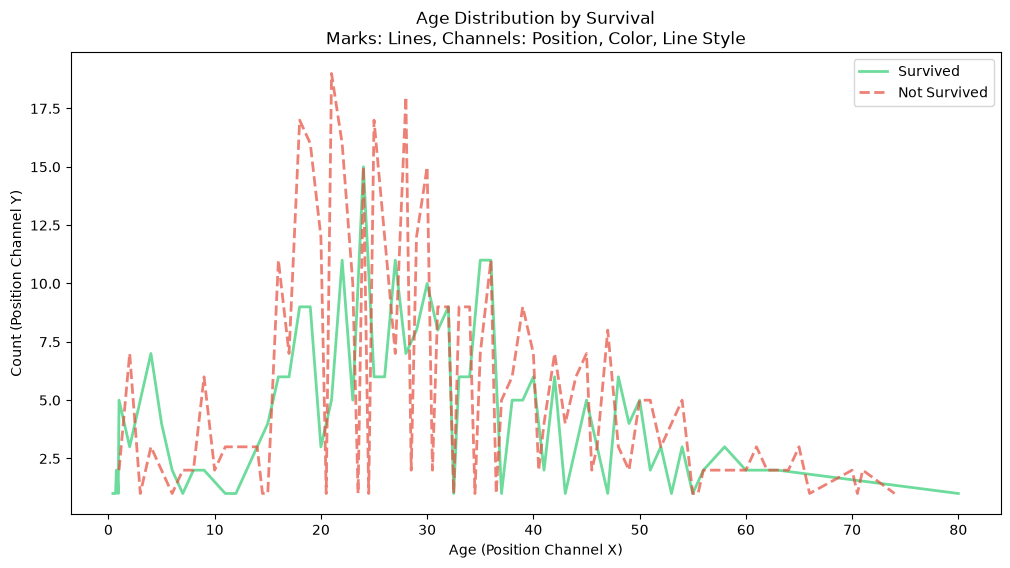

In [14]:
# Example 3: Line Plot with Visual Encoding
# Mark type: Lines (1D)
# Channels: Position (x,y), Color, Line Style
plt.figure(figsize=(12, 6))

# Calculate age distribution for survived and not survived
age_survived = df[df['survived'] == 1]['age'].value_counts().sort_index()
age_not_survived = df[df['survived'] == 0]['age'].value_counts().sort_index()

# Plot lines with different channels
plt.plot(age_survived.index, age_survived.values, 
         color='#2ecc71', linewidth=2, linestyle='-', 
         label='Survived', alpha=0.7)
plt.plot(age_not_survived.index, age_not_survived.values, 
         color='#e74c3c', linewidth=2, linestyle='--', 
         label='Not Survived', alpha=0.7)

plt.title('Age Distribution by Survival\nMarks: Lines, Channels: Position, Color, Line Style')
plt.xlabel('Age (Position Channel X)')
plt.ylabel('Count (Position Channel Y)')
plt.legend()

plt.show()


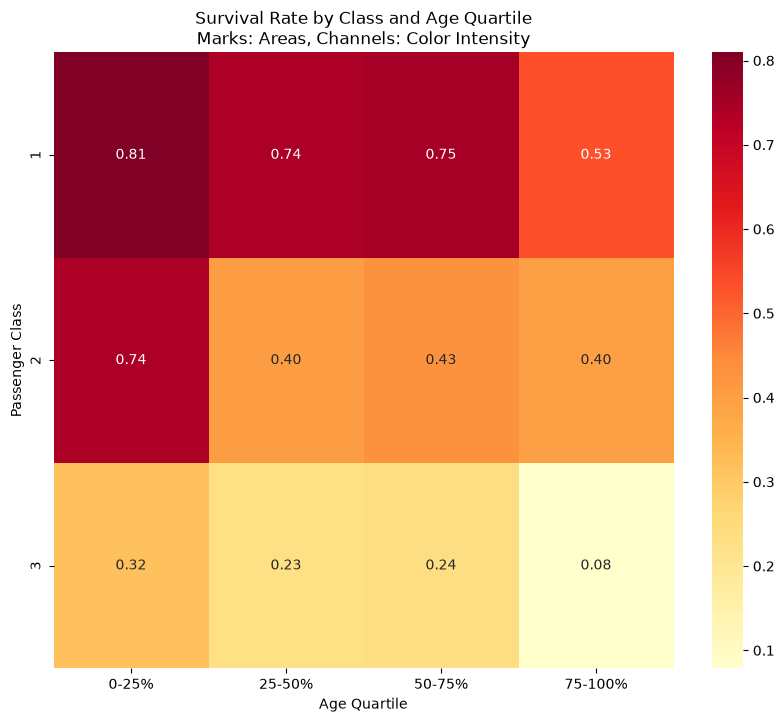

In [17]:
# Example 4: Heatmap using Area Marks and Color Channel
# Mark type: 2D Areas
# Channels: Position (x,y), Color Intensity
plt.figure(figsize=(10, 8))

# Create a pivot table for the heatmap with explicit observed parameter
heatmap_data = df.pivot_table(
    index='pclass', 
    columns=pd.qcut(df['age'], 4, labels=['0-25%', '25-50%', '50-75%', '75-100%']),
    values='survived', 
    aggfunc='mean',
    observed=False  # Explicitly set observed parameter to maintain current behavior
)

# Create heatmap
sns.heatmap(heatmap_data, annot=True, cmap='YlOrRd', fmt='.2f')

plt.title('Survival Rate by Class and Age Quartile\nMarks: Areas, Channels: Color Intensity')
plt.xlabel('Age Quartile')
plt.ylabel('Passenger Class')

plt.show()


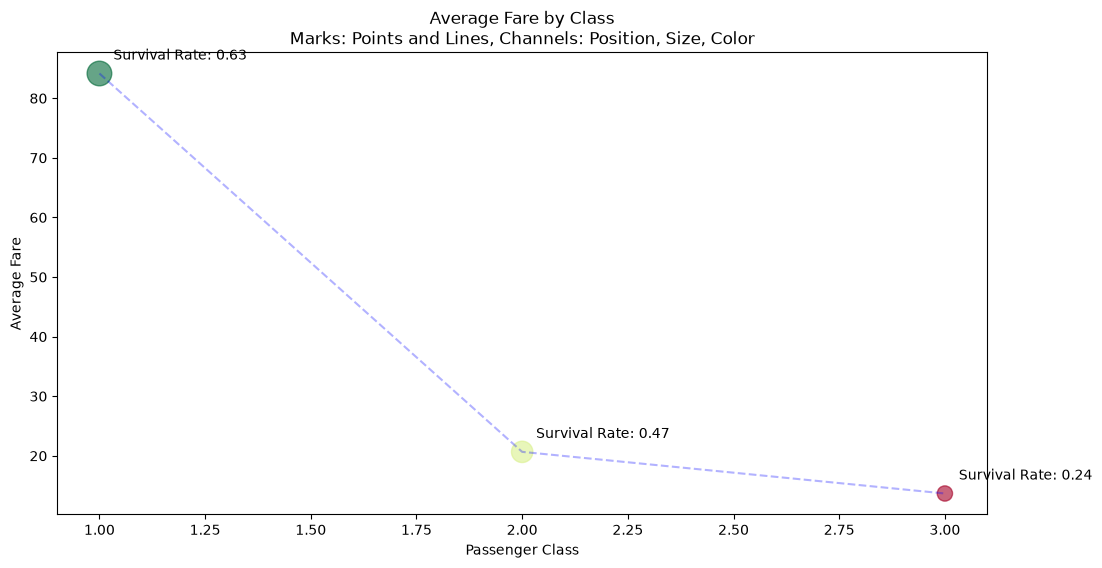

In [20]:
 #Example 5: Compound Marks with Multiple Channels
# Mark types: Points and Lines
# Channels: Position, Color, Size, Shape
plt.figure(figsize=(12, 6))

# Calculate average fare and survival rate by passenger class
class_stats = df.groupby('pclass').agg({
    'fare': 'mean',
    'survived': 'mean'
}).reset_index()

# Plot points (circles) for each class
plt.scatter(class_stats['pclass'], 
           class_stats['fare'], 
           s=class_stats['survived'] * 500,  # Size channel based on survival rate
           c=class_stats['survived'],  # Color channel
           cmap='RdYlGn',
           alpha=0.6)

# Connect points with lines
plt.plot(class_stats['pclass'], 
         class_stats['fare'], 
         'b--', 
         alpha=0.3)

# Add labels and title
plt.title('Average Fare by Class\nMarks: Points and Lines, Channels: Position, Size, Color')
plt.xlabel('Passenger Class')
plt.ylabel('Average Fare')

# Add text labels for survival rates
for idx, row in class_stats.iterrows():
    plt.annotate(f'Survival Rate: {row["survived"]:.2f}',
                (row['pclass'], row['fare']),
                xytext=(10, 10),
                textcoords='offset points')

plt.show()



## Exercises


**1: Basic Bar Chart Encoding**

**Objective:** Understand the use of 2D marks (bars) with position and colour channels.

**Task:** Create a bar chart that shows:

- The distribution of passengers by gender

- Use different colours for survived vs not survived

- Add proper labels and a legend

- Include a title that explicitly mentions the marks and channels used

**Requirements:**

1. Use plt.bar() with appropriate width spacing
2. Choose contrasting colours (e.g., #e74c3c and #2ecc71)
3. Include percentage labels on top of each bar
4. Add a brief explanation of why you chose these specific visual channels


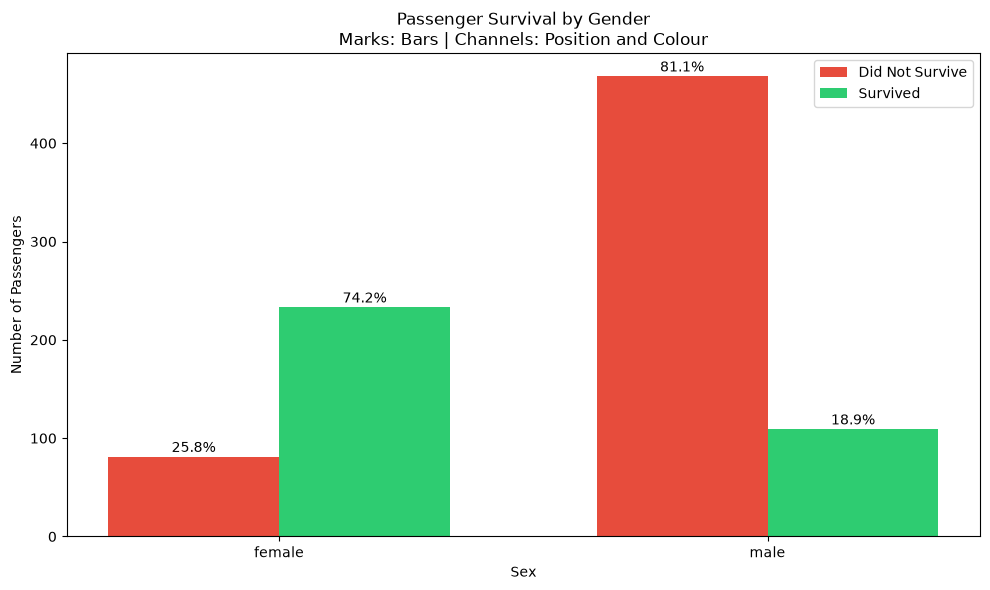

In [ ]:


#Start your solution


# Exercise 1: Basic Bar Chart Encoding

# Calculate gender distribution with survival
gender_survival = (
    df.groupby(['sex', 'survived'])
    .size()
    .unstack()
)

# Calculate percentages for each gender
gender_percentages = gender_survival.div(
    gender_survival.sum(axis=1),
    axis=0
) * 100

# Bar positions
x = np.arange(len(gender_survival.index))
width = 0.35

plt.figure(figsize=(10, 6))

# Did not survive
bars1 = plt.bar(
    x - width / 2,
    gender_survival[0],
    width,
    color='#e74c3c',
    label='Did Not Survive'
)

# Survived
bars2 = plt.bar(
    x + width / 2,
    gender_survival[1],
    width,
    color='#2ecc71',
    label='Survived'
)

# Add percentage labels
for i in range(len(gender_survival)):
    plt.text(
        x[i] - width / 2,
        gender_survival.iloc[i, 0] + 5,
        f"{gender_percentages.iloc[i, 0]:.1f}%",
        ha='center'
    )

    plt.text(
        x[i] + width / 2,
        gender_survival.iloc[i, 1] + 5,
        f"{gender_percentages.iloc[i, 1]:.1f}%",
        ha='center'
    )

# Labels and title
plt.title(
    'Passenger Survival by Gender\n'
    'Marks: Bars | Channels: Position and Colour'
)

plt.xlabel('Sex')
plt.ylabel('Number of Passengers')

plt.xticks(
    x,
    gender_survival.index
)

plt.legend()

plt.tight_layout()
plt.show()


**2: Multi-Channel Scatter Plot**

**Objective:** Explore how to combine multiple channels (position, colour, size) effectively.

**Task:** Create a scatter plot that visualises:

- Age vs Fare on x and y axes
- Survival status using colour
- Family size (Siblings/Spouses + Parents/Children) using point size
- Different passenger classes using different marker shapes

**Requirements:**
1. Use plt.scatter() with at least 3 different visual channels
2. Create a comprehensive legend explaining each channel
3. Handle missing values appropriately
4. Add annotations for any interesting outliers


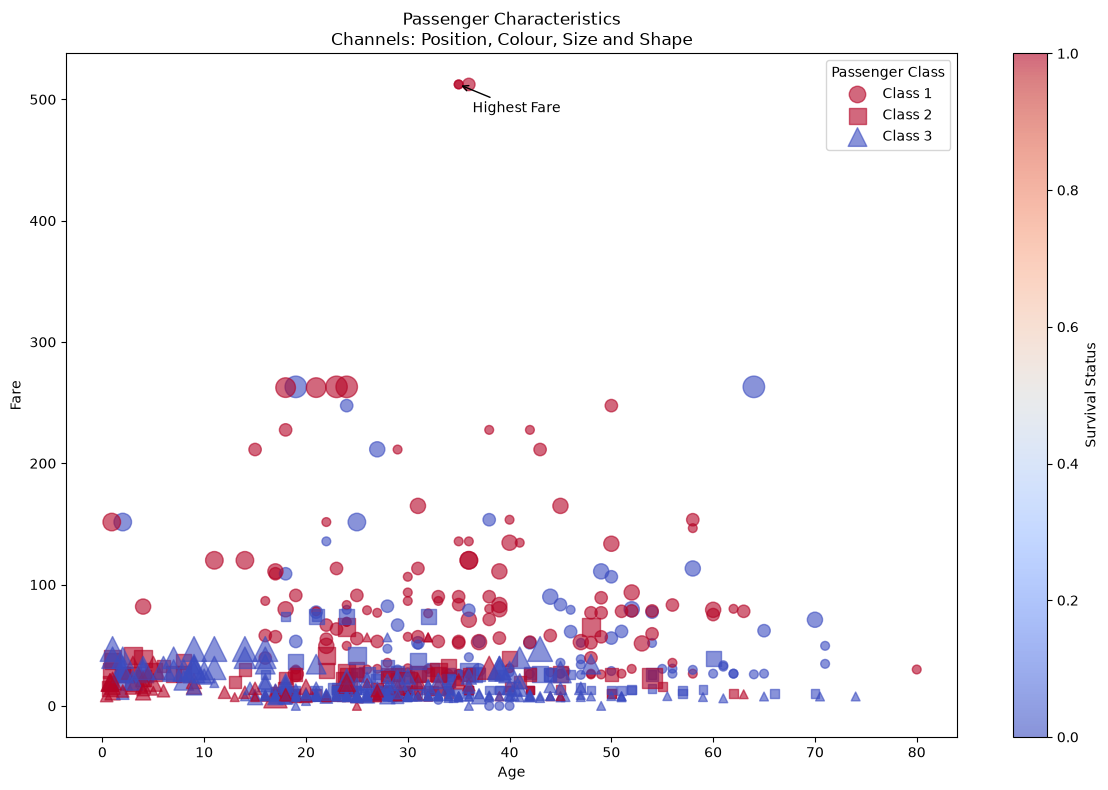

In [26]:
# Calculate total family size
df['familySize'] = df['sibsp'] + df['parch']

#Start your solution

# Keep rows where age and fare are available
plot_data = df[
    ['age', 'fare', 'survived', 'familySize', 'pclass']
].dropna()

# Marker shape for each passenger class
markers = {
    1: 'o',
    2: 's',
    3: '^'
}

plt.figure(figsize=(12, 8))

# Plot each passenger class separately
for passenger_class in [1, 2, 3]:

    class_data = plot_data[
        plot_data['pclass'] == passenger_class
    ]

    scatter = plt.scatter(
        class_data['age'],
        class_data['fare'],
        c=class_data['survived'],
        s=class_data['familySize'] * 40 + 40,
        marker=markers[passenger_class],
        cmap='coolwarm',
        alpha=0.6,
        label=f'Class {passenger_class}'
    )

# Add colour bar for survival
colorbar = plt.colorbar(scatter)
colorbar.set_label('Survival Status')

# Add labels and title
plt.title(
    'Passenger Characteristics\n'
    'Channels: Position, Colour, Size and Shape'
)

plt.xlabel('Age')
plt.ylabel('Fare')

plt.legend(title='Passenger Class')

# Find and annotate the passenger with the highest fare
highest_fare = plot_data.loc[
    plot_data['fare'].idxmax()
]

plt.annotate(
    'Highest Fare',
    (highest_fare['age'], highest_fare['fare']),
    xytext=(10, -20),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->')
)

plt.tight_layout()
plt.show()


**3: Age Distribution Analysis**

**Objective:** Learn to use line marks with multiple channels for distribution comparison.

**Task:** Create a dual-line plot showing:

- Age distribution for survived vs not survived passengers
- Use different line styles and colours
- Add markers at significant points (e.g., peaks)
- Include confidence intervals or error bands

**Requirements:**
1. Use kernel density estimation (KDE) for smooth distributions
2. Implement at least two different line styles
3. Add vertical lines for mean ages
4. Include annotations explaining key findings



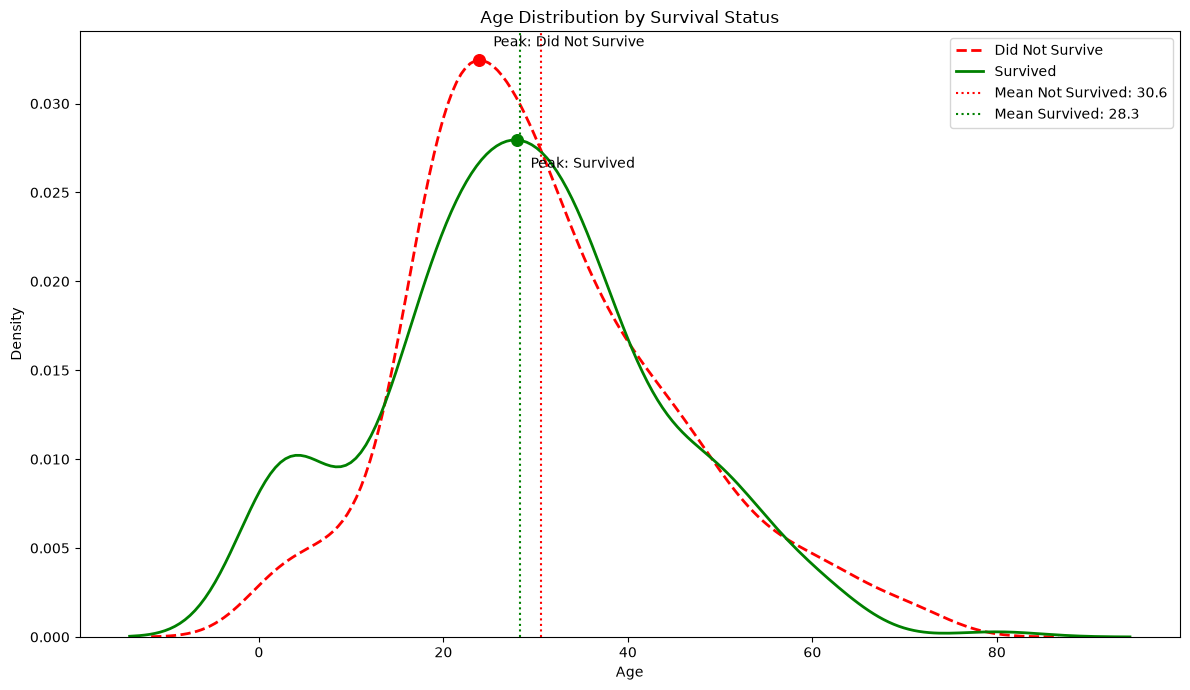

In [30]:
# Exercise 3: Age Distribution Analysis

# Remove missing ages
age_data = df[['age', 'survived']].dropna()

# Separate survived and not survived
survived_ages = age_data[
    age_data['survived'] == 1
]['age']

not_survived_ages = age_data[
    age_data['survived'] == 0
]['age']

plt.figure(figsize=(12, 7))

# Plot KDE lines
sns.kdeplot(
    not_survived_ages,
    color='red',
    linestyle='--',
    linewidth=2,
    fill=False,
    label='Did Not Survive'
)

sns.kdeplot(
    survived_ages,
    color='green',
    linestyle='-',
    linewidth=2,
    fill=False,
    label='Survived'
)

# Mean ages
mean_not_survived = not_survived_ages.mean()
mean_survived = survived_ages.mean()

# Add mean lines
plt.axvline(
    mean_not_survived,
    color='red',
    linestyle=':',
    label=f'Mean Not Survived: {mean_not_survived:.1f}'
)

plt.axvline(
    mean_survived,
    color='green',
    linestyle=':',
    label=f'Mean Survived: {mean_survived:.1f}'
)

# Get the two KDE lines
lines = plt.gca().lines

not_survived_line = lines[0]
survived_line = lines[1]

# Get x and y values
not_survived_x = not_survived_line.get_xdata()
not_survived_y = not_survived_line.get_ydata()

survived_x = survived_line.get_xdata()
survived_y = survived_line.get_ydata()

# Find peak positions
not_survived_peak_index = np.argmax(not_survived_y)
survived_peak_index = np.argmax(survived_y)

not_survived_peak_x = not_survived_x[not_survived_peak_index]
not_survived_peak_y = not_survived_y[not_survived_peak_index]

survived_peak_x = survived_x[survived_peak_index]
survived_peak_y = survived_y[survived_peak_index]

# Add peak markers
plt.scatter(
    not_survived_peak_x,
    not_survived_peak_y,
    color='red',
    s=70
)

plt.scatter(
    survived_peak_x,
    survived_peak_y,
    color='green',
    s=70
)

# Add annotations
plt.annotate(
    'Peak: Did Not Survive',
    (not_survived_peak_x, not_survived_peak_y),
    xytext=(10, 10),
    textcoords='offset points'
)

plt.annotate(
    'Peak: Survived',
    (survived_peak_x, survived_peak_y),
    xytext=(10, -20),
    textcoords='offset points'
)

plt.title('Age Distribution by Survival Status')
plt.xlabel('Age')
plt.ylabel('Density')

plt.legend()
plt.tight_layout()

plt.show()


**4: Survival Rate Heatmapr**

**Objective:** Master the use of 2D area marks with colour intensity channels.

**Task:** Create a heatmap that shows:

- Survival rates by passenger class and age groups
- Use an appropriate colour scheme
- Include actual values in each cell
- Add row and column totals

**Requirements:**
1. Create meaningful age groups (at least 4 categories)
2. Use a sequential colour scheme
3. Add annotations for the highest and lowest survival rates
4. Include proper labels and a colour bar

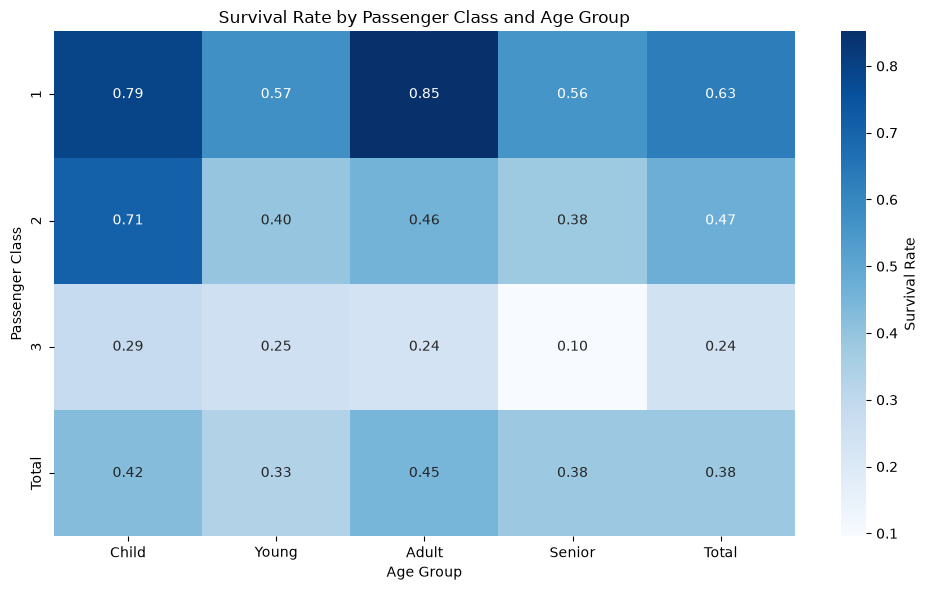

In [ ]:


#Start your solution



# Exercise 4: Survival Rate Heatmap

# Create age categories
df['AgeGroup'] = pd.qcut(
    df['age'].fillna(df['age'].mean()),
    q=4,
    labels=['Child', 'Young', 'Adult', 'Senior']
)

# Calculate survival rates
survival_heatmap = pd.pivot_table(
    df,
    values='survived',
    index='pclass',
    columns='AgeGroup',
    aggfunc='mean',
    observed=False
)

# Add row totals
survival_heatmap['Total'] = (
    df.groupby('pclass')['survived']
    .mean()
)

# Add column totals
column_totals = (
    df.groupby('AgeGroup', observed=False)['survived']
    .mean()
)

# Add total row
survival_heatmap.loc['Total'] = [
    column_totals['Child'],
    column_totals['Young'],
    column_totals['Adult'],
    column_totals['Senior'],
    df['survived'].mean()
]

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    survival_heatmap,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    cbar_kws={'label': 'Survival Rate'}
)

plt.title('Survival Rate by Passenger Class and Age Group')
plt.xlabel('Age Group')
plt.ylabel('Passenger Class')

plt.tight_layout()
plt.show()

**5: Combined Visualisation Challenge**

**Objective:** Demonstrate understanding of multiple marks and channels in a single visualisation.

**Task:** Create a compound visualisation that shows:

- Fare distribution across classes using box plots
- Overlay individual points for surviving passengers
- Add violin plots to show the distribution shape
- Include summary statistics

**Requirements:**
1. Combine at least three different types of marks
2. Use appropriate channels for each mark type
3. Create an informative legend
4. Add statistical annotations (mean, median, etc.)
5. Handle outliers appropriately

In [ ]:
#Start your solution